# Customer Churn Prediction Using Artificial Neural Network (ANN)

## Phase 1 – Data Understanding


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("cleaned_customerchurn_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (180, 13)


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            180 non-null    object 
 1   Age                    180 non-null    float64
 2   Annual_Income          180 non-null    float64
 3   Tenure_Months          180 non-null    float64
 4   Monthly_Charges        180 non-null    float64
 5   Support_Calls_Last_3M  180 non-null    float64
 6   Data_Usage_GB          180 non-null    float64
 7   Satisfaction_Score     180 non-null    float64
 8   Contract_Type          180 non-null    object 
 9   Payment_Method         180 non-null    object 
 10  Region                 180 non-null    object 
 11  Plan_Type              180 non-null    object 
 12  Churn                  180 non-null    object 
dtypes: float64(7), object(6)
memory usage: 18.4+ KB


In [4]:
print("Numerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical Columns:
['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']

Categorical Columns:
['Customer_ID', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Customer_ID              0
Age                      0
Annual_Income            0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
Contract_Type            0
Payment_Method           0
Region                   0
Plan_Type                0
Churn                    0
dtype: int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
df.describe()

,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,36.311111,65188.333333,38.627778,74.508333,3.055556,18.667222,5.761111
std,8.561502,21655.753296,19.372569,26.184246,1.584570,8.142247,2.811318
min,18.000000,8600.000000,1.000000,0.000000,0.000000,0.800000,1.000000
25%,31.000000,50800.000000,25.000000,58.035000,2.000000,13.150000,4.000000
50%,36.000000,64700.000000,38.000000,72.900000,3.000000,18.800000,6.000000
75%,41.000000,76650.000000,53.250000,88.750000,4.000000,24.125000,8.000000
max,63.000000,120900.000000,72.000000,151.180000,7.000000,44.000000,10.000000


In [8]:
categorical_columns = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type",
    "Churn"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Contract_Type
Contract_Type
Monthly    104
1 Year      52
2 Year      24
Name: count, dtype: int64

 Payment_Method
Payment_Method
UPI              48
Bank Transfer    46
Credit Card      44
Debit Card       41
Unknown           1
Name: count, dtype: int64

 Region
Region
North    51
South    49
West     46
East     34
Name: count, dtype: int64

 Plan_Type
Plan_Type
Standard    94
Basic       47
Premium     39
Name: count, dtype: int64

 Churn
Churn
Yes    94
No     86
Name: count, dtype: int64


Churn
Yes    94
No     86
Name: count, dtype: int64


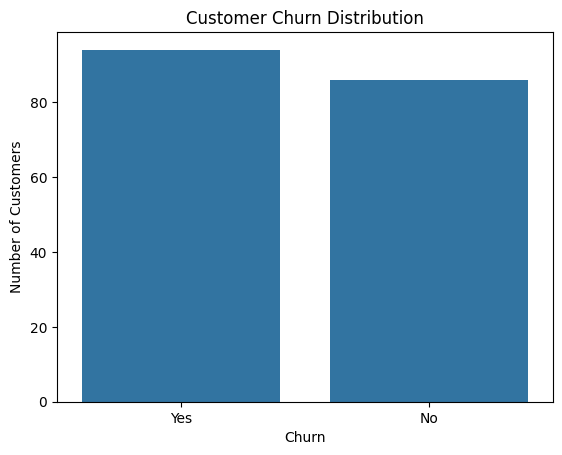

In [9]:
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

## Phase 2 – Data Preprocessing

### Remove Unnecessary Columns

Customer_ID is only an identifier. It does not provide useful information for predicting customer churn, so we remove it.

In [10]:
df = df.drop("Customer_ID", axis=1)

print("Customer_ID removed successfully.")
print("Updated shape:", df.shape)

df.head()

Customer_ID removed successfully.
Updated shape: (180, 12)


,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


### Step 2 – Encode the Target Variable

The Churn column contains Yes and No values.

We convert:
- Yes = 1 (Customer Churned)
- No = 0 (Customer Stayed)

In [11]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df["Churn"].value_counts())

Churn
1    94
0    86
Name: count, dtype: int64


### Step 3 – Separate Features and Target

X contains the input features used for prediction.

y contains the target variable that the ANN will predict.

In [12]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (180, 11)
Target shape: (180,)


### Identify numerical and categorical features

In [13]:
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()

categorical_columns = X.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']

Categorical columns: ['Contract_Type', 'Payment_Method', 'Region', 'Plan_Type']


## Phase 3 – Exploratory Data Analysis (EDA)

EDA helps us understand the distribution of customer data and identify patterns related to customer churn.

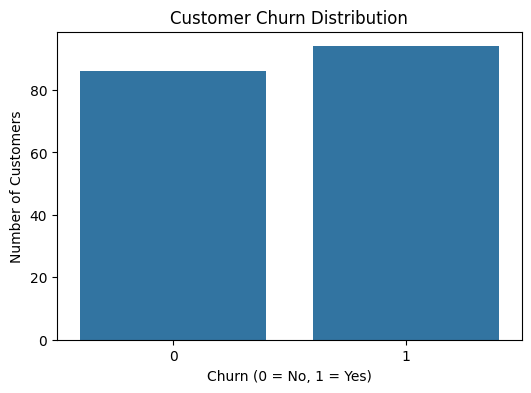

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

### Churn percentage

In [15]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Churn Percentage:")
print(churn_percentage)

Churn Percentage:
Churn
1    52.222222
0    47.777778
Name: proportion, dtype: float64


### Age vs Churn

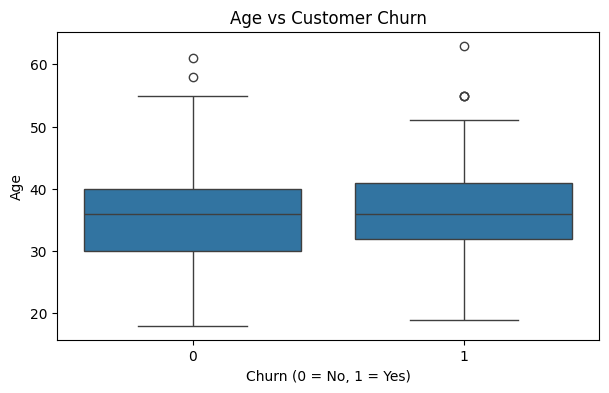

In [16]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="Churn", y="Age")

plt.title("Age vs Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

### Contract Type vs Churn

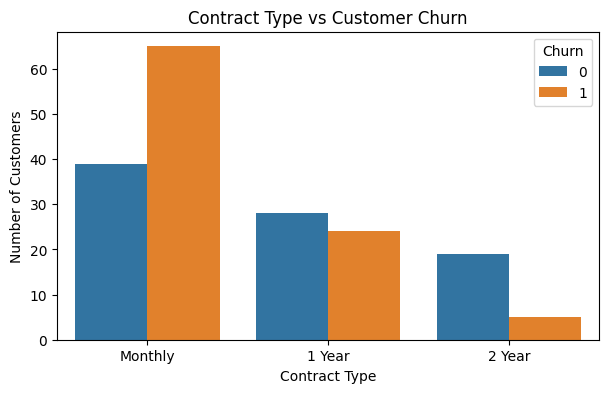

In [17]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="Contract_Type", hue="Churn")

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

### Monthly Charges vs Churn

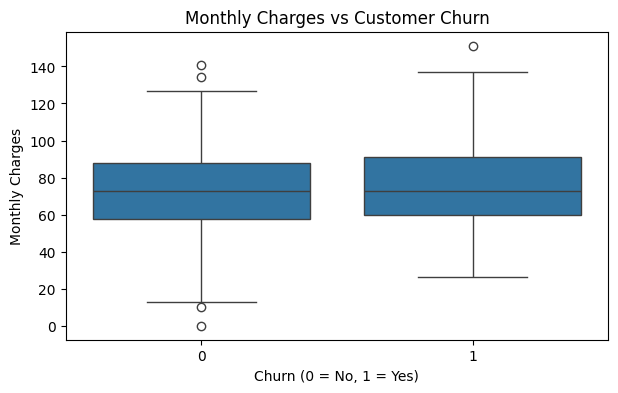

In [18]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="Churn", y="Monthly_Charges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")

plt.show()

### Satisfaction Score vs Churn

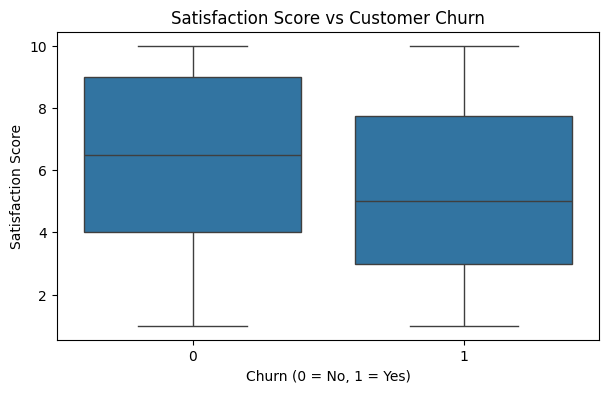

In [19]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="Churn", y="Satisfaction_Score")

plt.title("Satisfaction Score vs Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Satisfaction Score")

plt.show()

### Support Calls vs Churn

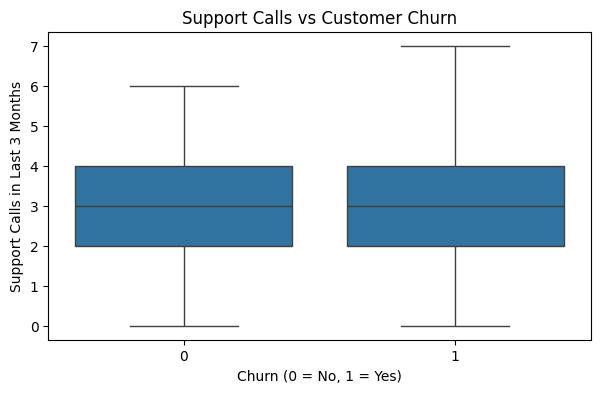

In [20]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="Churn", y="Support_Calls_Last_3M")

plt.title("Support Calls vs Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Support Calls in Last 3 Months")

plt.show()

### Correlation heatmap

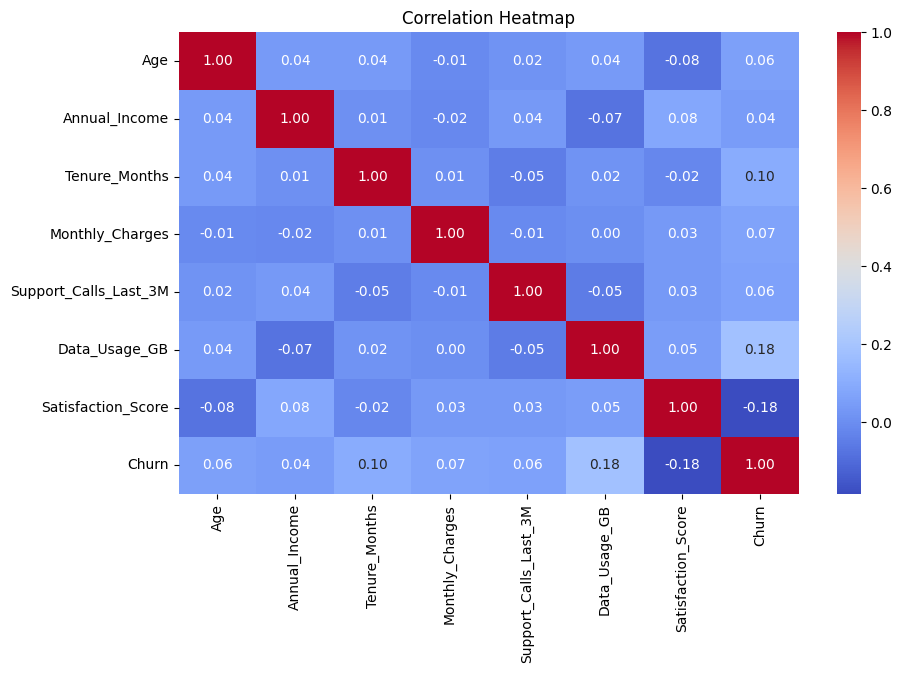

In [21]:
plt.figure(figsize=(10, 6))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Phase 4 – Data Splitting


We use stratified splitting to maintain the proportion of churn and non-churn customers in each set.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Temporary data shape:", X_temp.shape)

Training data shape: (126, 11)
Temporary data shape: (54, 11)


### plit validation and testing data

In [23]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

Validation data shape: (27, 11)
Testing data shape: (27, 11)


In [24]:
print("Total records:", len(X))

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation percentage:", round(len(X_val) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Total records: 180

Training records: 126
Validation records: 27
Testing records: 27

Training percentage: 70.0 %
Validation percentage: 15.0 %
Testing percentage: 15.0 %


In [25]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
Churn
1    66
0    60
Name: count, dtype: int64

Validation target distribution:
Churn
1    14
0    13
Name: count, dtype: int64

Testing target distribution:
Churn
1    14
0    13
Name: count, dtype: int64


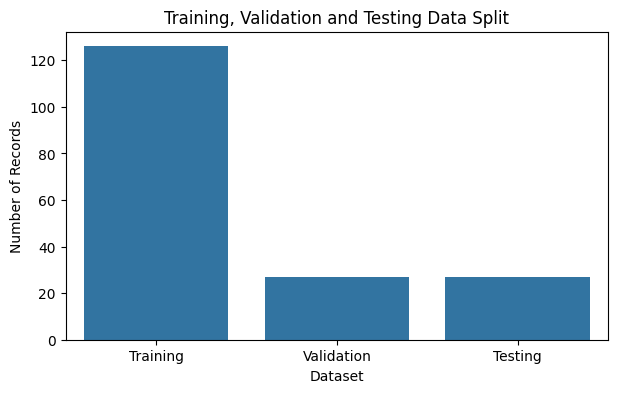

In [26]:
split_data = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Records": [len(X_train), len(X_val), len(X_test)]
})

plt.figure(figsize=(7, 4))

sns.barplot(data=split_data, x="Dataset", y="Records")

plt.title("Training, Validation and Testing Data Split")
plt.xlabel("Dataset")
plt.ylabel("Number of Records")

plt.show()

## Phase 5 – Feature Transformation

We use One-Hot Encoding for categorical features and StandardScaler for numerical features.

In [27]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
import pandas as pd

In [28]:
numerical_columns = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_columns = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']

Categorical Columns:
['Contract_Type', 'Payment_Method', 'Region', 'Plan_Type']


### One-Hot Encoding


In [29]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = [
    'Contract_Type',
    'Payment_Method',
    'Region',
    'Plan_Type'
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit encoder on training data
X_train_encoded = encoder.fit_transform(X_train[categorical_columns])

# Transform validation and testing data
X_val_encoded = encoder.transform(X_val[categorical_columns])
X_test_encoded = encoder.transform(X_test[categorical_columns])

print("Training encoded shape:", X_train_encoded.shape)
print("Validation encoded shape:", X_val_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)

Training encoded shape: (126, 15)
Validation encoded shape: (27, 15)
Testing encoded shape: (27, 15)


### Feature Scaling


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[numerical_columns])

X_val_scaled = scaler.transform(X_val[numerical_columns])

X_test_scaled = scaler.transform(X_test[numerical_columns])

print("Training scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (126, 7)
Validation scaled shape: (27, 7)
Testing scaled shape: (27, 7)


### Combine Transformed Features


In [31]:
X_train_final = np.concatenate(
    [X_train_scaled, X_train_encoded],
    axis=1
)

X_val_final = np.concatenate(
    [X_val_scaled, X_val_encoded],
    axis=1
)

X_test_final = np.concatenate(
    [X_test_scaled, X_test_encoded],
    axis=1
)

print("Final Training Shape:", X_train_final.shape)
print("Final Validation Shape:", X_val_final.shape)
print("Final Testing Shape:", X_test_final.shape)

Final Training Shape: (126, 22)
Final Validation Shape: (27, 22)
Final Testing Shape: (27, 22)


In [32]:
print("Training data:")
print("Shape:", X_train_final.shape)
print("Missing values:", np.isnan(X_train_final).sum())

print("\nValidation data:")
print("Shape:", X_val_final.shape)
print("Missing values:", np.isnan(X_val_final).sum())

print("\nTesting data:")
print("Shape:", X_test_final.shape)
print("Missing values:", np.isnan(X_test_final).sum())

Training data:
Shape: (126, 22)
Missing values: 0

Validation data:
Shape: (27, 22)
Missing values: 0

Testing data:
Shape: (27, 22)
Missing values: 0


In [33]:
scaled_summary = pd.DataFrame(
    X_train_scaled,
    columns=numerical_columns
)

print("Mean of scaled training features:")
print(scaled_summary.mean().round(2))

print("\nStandard deviation of scaled training features:")
print(scaled_summary.std().round(2))

Mean of scaled training features:
Age                     -0.0
Annual_Income            0.0
Tenure_Months            0.0
Monthly_Charges          0.0
Support_Calls_Last_3M   -0.0
Data_Usage_GB           -0.0
Satisfaction_Score      -0.0
dtype: float64

Standard deviation of scaled training features:
Age                      1.0
Annual_Income            1.0
Tenure_Months            1.0
Monthly_Charges          1.0
Support_Calls_Last_3M    1.0
Data_Usage_GB            1.0
Satisfaction_Score       1.0
dtype: float64


## Phase 6 – ANN Architecture


In [34]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Fix random seeds so results are reproducible
tf.keras.utils.set_random_seed(42)

### Prepare ANN input arrays

We use the transformed features from Phase 5 (scaled numerical + one-hot encoded categorical)
and convert them to `float32`, the data type TensorFlow expects.

In [35]:
X_train_ann = X_train_final.astype(np.float32)
X_val_ann = X_val_final.astype(np.float32)
X_test_ann = X_test_final.astype(np.float32)

y_train_ann = y_train.to_numpy().astype(np.float32)
y_val_ann = y_val.to_numpy().astype(np.float32)
y_test_ann = y_test.to_numpy().astype(np.float32)

input_size = X_train_ann.shape[1]
feature_names = numerical_columns + encoder.get_feature_names_out(categorical_columns).tolist()

print("Number of input features:", input_size)
print("Training:", X_train_ann.shape, "Validation:", X_val_ann.shape, "Testing:", X_test_ann.shape)

Number of input features: 22
Training: (126, 22) Validation: (27, 22) Testing: (27, 22)


### Build the ANN model

- **Input layer:** one neuron per input feature
- **Hidden layers:** 32 → 16 neurons with ReLU activation to learn non-linear patterns
- **Output layer:** 1 neuron with Sigmoid activation, giving the probability that a customer churns

In [36]:
model = Sequential([
    Input(shape=(input_size,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
], name="baseline_ann")

model.summary()

Model: "baseline_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281 (5.00 KB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 0 (0.00 B)

## Phase 7 – Model Training

### Compile the ANN model

- **Optimizer:** Adam
- **Loss:** Binary Crossentropy (two-class problem)
- **Metrics:** Accuracy and AUC

In [37]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

### Train the ANN model

In [38]:
history = model.fit(
    X_train_ann,
    y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=50,
    batch_size=16,
    verbose=0
)

print("Training finished.")
print("Final training accuracy:", round(history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))

Training finished.
Final training accuracy: 0.9286
Final validation accuracy: 0.4815


### Training and validation curves

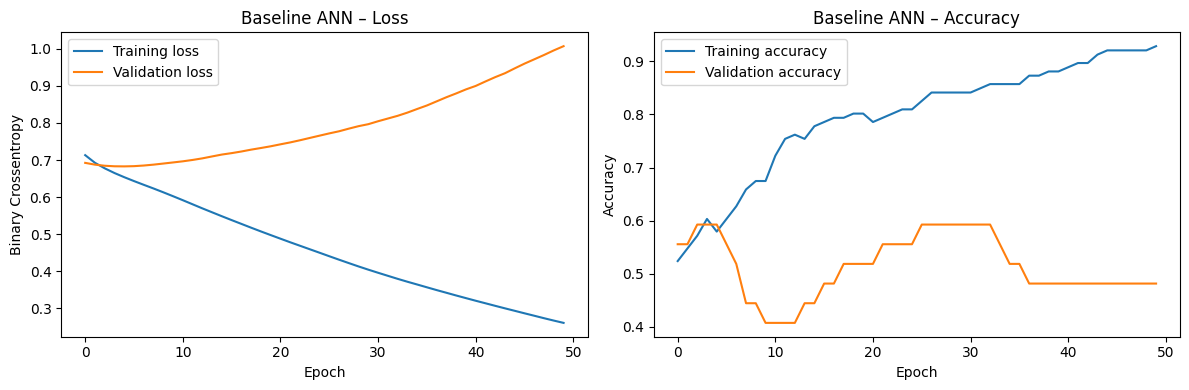

In [39]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["loss"], label="Training loss")
    axes[0].plot(history.history["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title} – Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary Crossentropy")
    axes[0].legend()

    axes[1].plot(history.history["accuracy"], label="Training accuracy")
    axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(f"{title} – Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history, "Baseline ANN")

## Phase 8 – Model Evaluation

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
# Predict churn probabilities on the unseen test set
y_probability = model.predict(X_test_ann, verbose=0).reshape(-1)

# Convert probabilities into binary predictions
y_pred = (y_probability >= 0.5).astype(int)

# Actual values
y_actual = y_test_ann.astype(int)

print("Predictions completed!")

Predictions completed!


In [42]:
from sklearn.metrics import roc_auc_score

accuracy = accuracy_score(y_actual, y_pred)
precision = precision_score(y_actual, y_pred, zero_division=0)
recall = recall_score(y_actual, y_pred, zero_division=0)
f1 = f1_score(y_actual, y_pred, zero_division=0)
auc = roc_auc_score(y_actual, y_probability)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC:", round(auc, 4))

baseline_results = {"Model": "Baseline ANN", "Accuracy": accuracy, "Precision": precision,
                    "Recall": recall, "F1-Score": f1, "ROC-AUC": auc}

Accuracy: 0.5185
Precision: 0.5294
Recall: 0.6429
F1-Score: 0.5806
ROC-AUC: 0.522


In [43]:
print(classification_report(
    y_actual,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.50      0.38      0.43        13
           1       0.53      0.64      0.58        14

    accuracy                           0.52        27
   macro avg       0.51      0.51      0.51        27
weighted avg       0.52      0.52      0.51        27



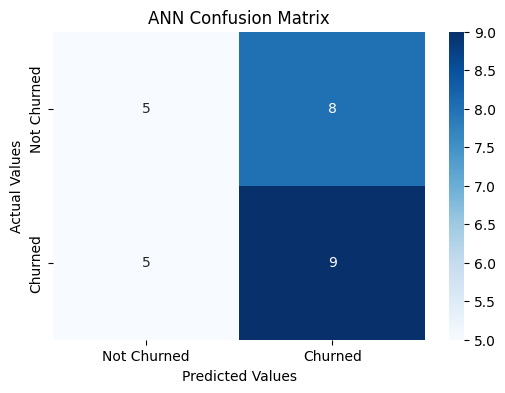

In [44]:
cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned']
)

plt.title('ANN Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [45]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 5
False Positives: 8
False Negatives: 5
True Positives: 9


## Phase 9 – Model Improvement

The baseline ANN may overfit because the dataset is small. We improve it with:

1. **Dropout** – randomly switches off neurons during training so the network cannot rely on any single neuron.
2. **Early Stopping** – stops training when validation loss stops improving and restores the best weights.
3. **Hyperparameter experiments** – try different hidden-layer sizes, dropout rates and learning rates,
   and choose the best configuration using the **validation set** (the test set stays untouched until the end).

### Helper function to build a model

In [46]:
def build_model(hidden_units=(32, 16), dropout_rate=0.3, learning_rate=0.001):
    layers = [Input(shape=(input_size,))]
    for units in hidden_units:
        layers.append(Dense(units, activation="relu"))
        if dropout_rate > 0:
            layers.append(Dropout(dropout_rate))
    layers.append(Dense(1, activation="sigmoid"))

    m = Sequential(layers)
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return m


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

### Improved model: Dropout + Early Stopping

Training stopped after 25 epochs


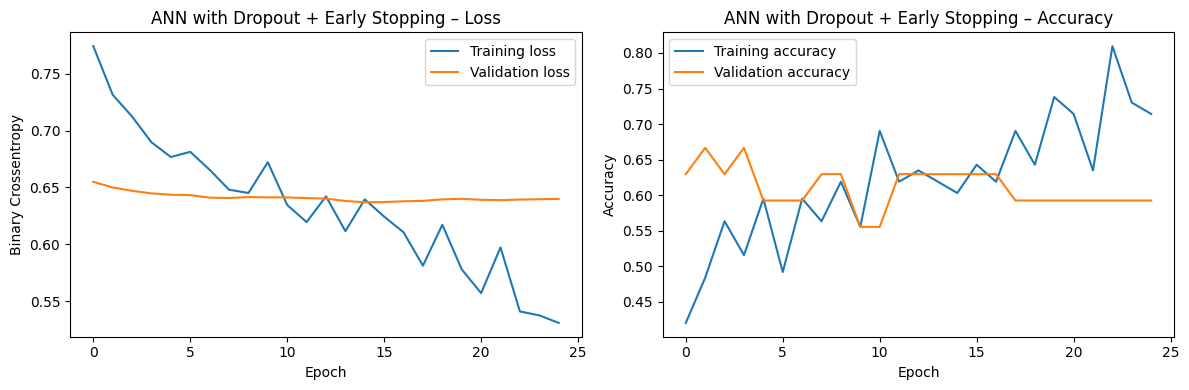

In [47]:
tf.keras.utils.set_random_seed(42)

improved_model = build_model(hidden_units=(32, 16), dropout_rate=0.3, learning_rate=0.001)

improved_history = improved_model.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=0
)

print("Training stopped after", len(improved_history.history["loss"]), "epochs")
plot_history(improved_history, "ANN with Dropout + Early Stopping")

### Hyperparameter experiments (5-fold cross-validation)

With only 27 validation customers, one prediction changes accuracy by 3.7 %, so picking settings from a
single validation split is mostly luck. Instead we use **stratified 5-fold cross-validation on the
training + validation data (153 customers)**. Each configuration is trained 5 times on different
folds and we average the ROC-AUC. The scaler and encoder are re-fitted inside every fold to avoid
data leakage. The test set is **still untouched**.

In [48]:
from itertools import product
from sklearn.model_selection import StratifiedKFold

X_dev_raw = pd.concat([X_train, X_val])
y_dev = np.concatenate([y_train_ann, y_val_ann])

def fit_transformers(df_fit):
    sc = StandardScaler().fit(df_fit[numerical_columns])
    enc = OneHotEncoder(categories=encoder.categories_, handle_unknown="ignore",
                        sparse_output=False).fit(df_fit[categorical_columns])
    def transform(df_t):
        return np.concatenate([sc.transform(df_t[numerical_columns]),
                               enc.transform(df_t[categorical_columns])], axis=1).astype(np.float32)
    return transform

hidden_options = [(16,), (32, 16), (64, 32)]
dropout_options = [0.0, 0.3]
learning_rate_options = [0.001, 0.01]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
experiment_results = []

for hidden_units, dropout_rate, learning_rate in product(hidden_options, dropout_options, learning_rate_options):
    fold_auc, fold_f1, fold_epochs = [], [], []
    for train_idx, hold_idx in cv.split(X_dev_raw, y_dev):
        transform = fit_transformers(X_dev_raw.iloc[train_idx])
        X_tr, X_ho = transform(X_dev_raw.iloc[train_idx]), transform(X_dev_raw.iloc[hold_idx])
        y_tr, y_ho = y_dev[train_idx], y_dev[hold_idx]

        tf.keras.utils.set_random_seed(42)
        m = build_model(hidden_units, dropout_rate, learning_rate)
        h = m.fit(X_tr, y_tr, validation_split=0.15, epochs=200, batch_size=16,
                  callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
                  verbose=0)
        prob = m.predict(X_ho, verbose=0).reshape(-1)
        fold_auc.append(roc_auc_score(y_ho, prob))
        fold_f1.append(f1_score(y_ho, (prob >= 0.5).astype(int), zero_division=0))
        fold_epochs.append(len(h.history["loss"]))

    experiment_results.append({
        "Hidden Layers": str(hidden_units),
        "Dropout": dropout_rate,
        "Learning Rate": learning_rate,
        "Avg Epochs": np.mean(fold_epochs),
        "CV AUC (mean)": np.mean(fold_auc),
        "CV AUC (std)": np.std(fold_auc),
        "CV F1 (mean)": np.mean(fold_f1),
    })

experiment_df = (pd.DataFrame(experiment_results)
                 .sort_values("CV AUC (mean)", ascending=False)
                 .reset_index(drop=True))
experiment_df.round(4)

,Hidden Layers,Dropout,Learning Rate,Avg Epochs,CV AUC (mean),CV AUC (std),CV F1 (mean)
0,"(32, 16)",0.3,0.010,14.6,0.6748,0.0334,0.7042
1,"(16,)",0.0,0.001,46.0,0.6724,0.0607,0.6446
2,"(32, 16)",0.3,0.001,35.6,0.6623,0.0834,0.6605
3,"(16,)",0.3,0.010,14.2,0.6620,0.0889,0.6625
4,"(16,)",0.0,0.010,13.6,0.6565,0.0585,0.5882
5,"(16,)",0.3,0.001,59.6,0.6445,0.0573,0.6510
6,"(32, 16)",0.0,0.010,12.4,0.6382,0.0513,0.6591
7,"(64, 32)",0.0,0.001,20.6,0.6229,0.0820,0.5945
8,"(64, 32)",0.3,0.001,33.8,0.6110,0.0720,0.6500
9,"(32, 16)",0.0,0.001,23.4,0.5996,0.0320,0.5437


### Visualise the experiments

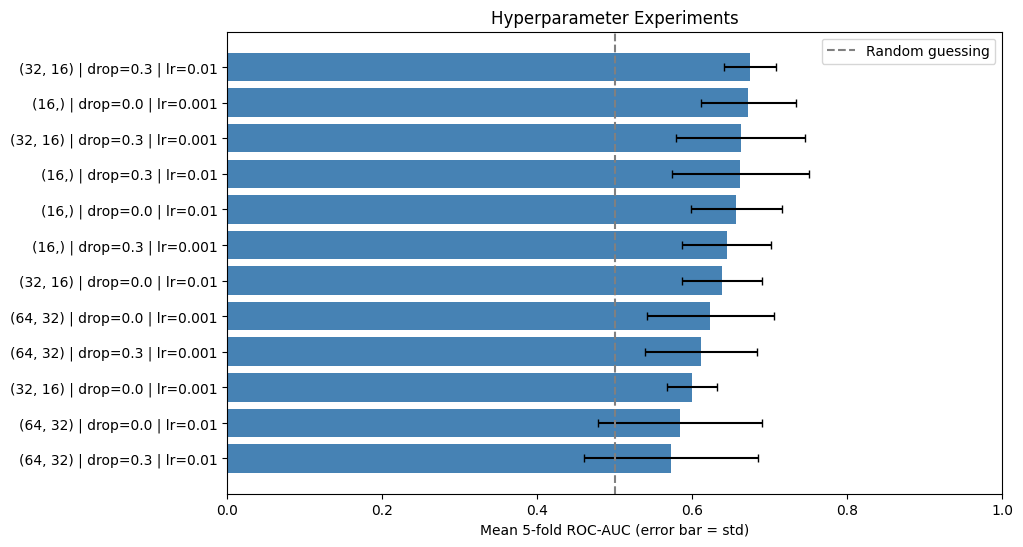

In [49]:
plot_df = experiment_df.copy()
plot_df["Config"] = (plot_df["Hidden Layers"] + " | drop=" + plot_df["Dropout"].astype(str)
                     + " | lr=" + plot_df["Learning Rate"].astype(str))

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Config"], plot_df["CV AUC (mean)"], xerr=plot_df["CV AUC (std)"],
         color="steelblue", capsize=3)
plt.axvline(0.5, color="grey", linestyle="--", label="Random guessing")
plt.gca().invert_yaxis()
plt.xlabel("Mean 5-fold ROC-AUC (error bar = std)")
plt.title("Hyperparameter Experiments")
plt.legend()
plt.xlim(0, 1)
plt.show()

### Train the best configuration and evaluate on the test set

Best configuration:
  Hidden layers: (32, 16)
  Dropout: 0.3
  Learning rate: 0.01


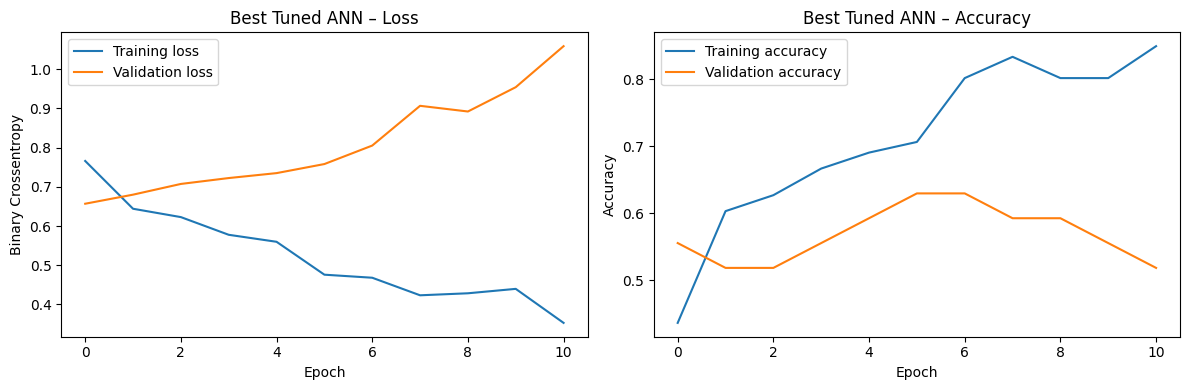

In [51]:
best = experiment_df.iloc[0]
best_hidden = tuple(int(u) for u in best["Hidden Layers"].strip("()").split(",") if u.strip())
best_dropout = float(best["Dropout"])
best_lr = float(best["Learning Rate"])

print("Best configuration:")
print("  Hidden layers:", best_hidden)
print("  Dropout:", best_dropout)
print("  Learning rate:", best_lr)

tf.keras.utils.set_random_seed(42)
best_model = build_model(best_hidden, best_dropout, best_lr)
best_history = best_model.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=200, batch_size=16,
    callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
    verbose=0
)
plot_history(best_history, "Best Tuned ANN")

In [52]:
def evaluate(m, name):
    prob = m.predict(X_test_ann, verbose=0).reshape(-1)
    pred = (prob >= 0.5).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_actual, pred),
        "Precision": precision_score(y_actual, pred, zero_division=0),
        "Recall": recall_score(y_actual, pred, zero_division=0),
        "F1-Score": f1_score(y_actual, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_actual, prob),
    }, pred

improved_results, _ = evaluate(improved_model, "Dropout + Early Stopping")
best_results, best_pred = evaluate(best_model, "Best Tuned ANN")

comparison_df = pd.DataFrame([baseline_results, improved_results, best_results]).set_index("Model")
comparison_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Baseline ANN,0.5185,0.5294,0.6429,0.5806,0.5220
Dropout + Early Stopping,0.4074,0.4444,0.5714,0.5000,0.4835
Best Tuned ANN,0.4444,0.4737,0.6429,0.5455,0.4121


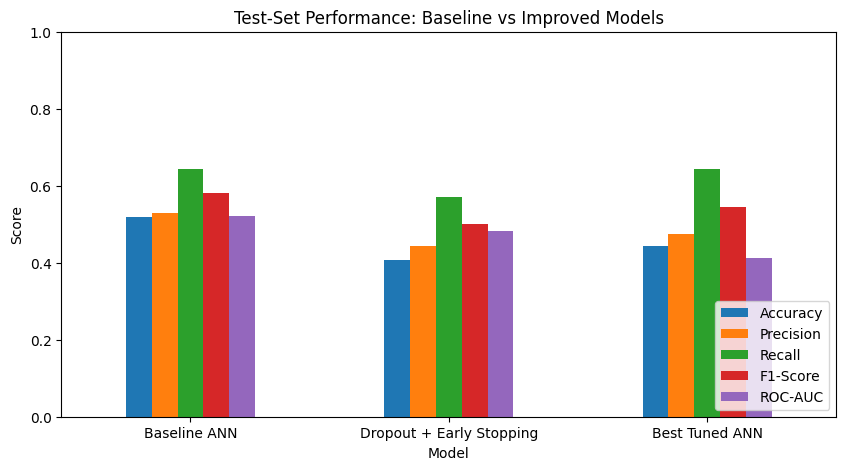

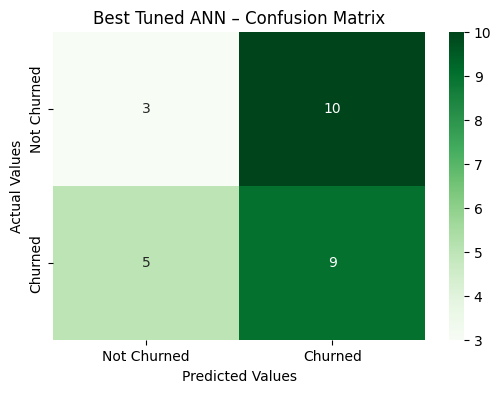

In [53]:
comparison_df.plot(kind="bar", figsize=(10, 5))
plt.title("Test-Set Performance: Baseline vs Improved Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

cm_best = confusion_matrix(y_actual, best_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Not Churned", "Churned"],
            yticklabels=["Not Churned", "Churned"])
plt.title("Best Tuned ANN – Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

## Phase 10 – Business Recommendations

To turn the model into business actions we need to know **which customer features drive churn**.
ANNs are not directly interpretable, so we use **permutation importance**: shuffle one feature at a time
and measure how much the model's ROC-AUC drops. A larger drop means the feature matters more.

To get stable estimates we repeat this on every held-out fold of the 5-fold cross-validation
(training the best configuration on the other 4 folds) and average the results.

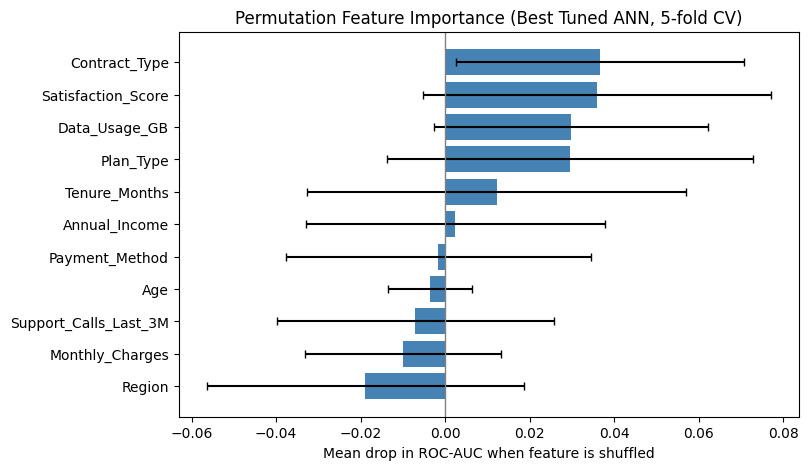

,Feature,AUC Drop,Std
0,Contract_Type,0.0366,0.0341
1,Satisfaction_Score,0.0359,0.0411
2,Data_Usage_GB,0.0298,0.0324
3,Plan_Type,0.0296,0.0433
4,Tenure_Months,0.0122,0.0448
5,Annual_Income,0.0024,0.0353
6,Payment_Method,-0.0016,0.0360
7,Age,-0.0036,0.0100
8,Support_Calls_Last_3M,-0.0071,0.0328
9,Monthly_Charges,-0.0100,0.0231


In [54]:
all_features = numerical_columns + categorical_columns
rng = np.random.default_rng(42)
fold_importances = []

for train_idx, hold_idx in cv.split(X_dev_raw, y_dev):
    transform = fit_transformers(X_dev_raw.iloc[train_idx])
    tf.keras.utils.set_random_seed(42)
    m = build_model(best_hidden, best_dropout, best_lr)
    m.fit(transform(X_dev_raw.iloc[train_idx]), y_dev[train_idx], validation_split=0.15,
          epochs=200, batch_size=16, verbose=0,
          callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])

    X_hold, y_hold = X_dev_raw.iloc[hold_idx], y_dev[hold_idx]
    base_auc = roc_auc_score(y_hold, m.predict(transform(X_hold), verbose=0).reshape(-1))

    drops = {}
    for feature in all_features:
        scores = []
        for _ in range(10):
            shuffled = X_hold.copy()
            shuffled[feature] = rng.permutation(shuffled[feature].values)
            scores.append(base_auc - roc_auc_score(y_hold, m.predict(transform(shuffled), verbose=0).reshape(-1)))
        drops[feature] = np.mean(scores)
    fold_importances.append(drops)

importance_df = (pd.DataFrame(fold_importances).agg(["mean", "std"]).T
                 .rename(columns={"mean": "AUC Drop", "std": "Std"})
                 .sort_values("AUC Drop", ascending=False)
                 .rename_axis("Feature").reset_index())

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["AUC Drop"], xerr=importance_df["Std"],
         color="steelblue", capsize=3)
plt.axvline(0, color="grey", linewidth=1)
plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance (Best Tuned ANN, 5-fold CV)")
plt.xlabel("Mean drop in ROC-AUC when feature is shuffled")
plt.show()

importance_df.round(4)

### Churn rate by key business segments

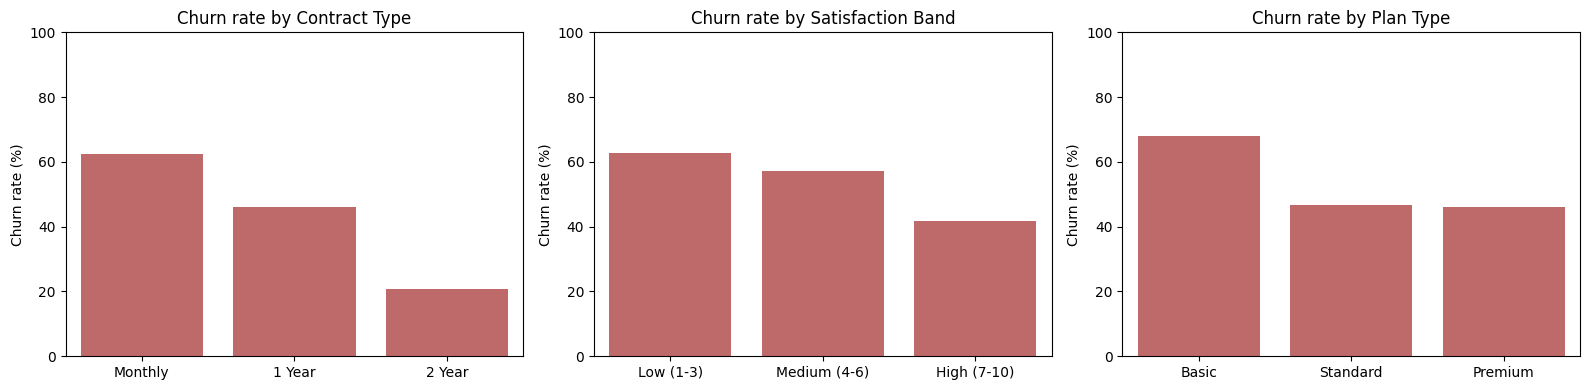

In [55]:
segment_df = df.copy()
segment_df["Satisfaction_Band"] = pd.cut(segment_df["Satisfaction_Score"], bins=[0, 3, 6, 10],
                                         labels=["Low (1-3)", "Medium (4-6)", "High (7-10)"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Contract_Type", "Satisfaction_Band", "Plan_Type"]):
    rate = segment_df.groupby(col, observed=True)["Churn"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="indianred")
    ax.set_title(f"Churn rate by {col.replace('_', ' ')}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

### Identify high-risk customers

In [56]:
# Score every test customer with the final model and rank by churn risk
risk_df = X_test.copy()
risk_df["Actual_Churn"] = y_actual
risk_df["Churn_Probability"] = best_model.predict(X_test_ann, verbose=0).reshape(-1)
# Split customers into three equal-sized groups by predicted risk
risk_df["Risk_Level"] = pd.qcut(risk_df["Churn_Probability"], q=3, labels=["Low", "Medium", "High"])

print(risk_df["Risk_Level"].value_counts())
risk_df.sort_values("Churn_Probability", ascending=False).head(10)

Risk_Level
Low       9
Medium    9
High      9
Name: count, dtype: int64


,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Actual_Churn,Churn_Probability,Risk_Level
117,25.0,94200.0,38.0,88.68,5.0,4.6,2.0,Monthly,Credit Card,West,Premium,0,0.699992,High
26,31.0,69100.0,36.0,91.65,1.0,25.4,7.0,Monthly,Debit Card,North,Basic,1,0.664877,High
80,55.0,96200.0,61.0,72.90,4.0,23.2,8.0,Monthly,Debit Card,West,Basic,0,0.632477,High
59,36.0,31300.0,26.0,70.33,0.0,37.9,5.0,Monthly,Debit Card,South,Basic,1,0.631808,High
52,42.0,67400.0,38.0,77.44,3.0,10.1,1.0,Monthly,Bank Transfer,South,Standard,0,0.622989,High
38,46.0,83300.0,68.0,65.12,5.0,28.6,6.0,Monthly,UPI,North,Standard,1,0.603299,High
0,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,1,0.584645,High
171,36.0,79200.0,47.0,60.09,2.0,19.7,1.0,Monthly,UPI,South,Standard,0,0.584384,High
157,51.0,40800.0,29.0,9.97,3.0,19.5,2.0,Monthly,Bank Transfer,North,Standard,0,0.564112,High
31,45.0,66700.0,64.0,55.39,4.0,8.4,7.0,1 Year,Bank Transfer,East,Standard,0,0.554324,Medium


### Interpretation of results

- **Model performance:** under 5-fold cross-validation the tuned ANN reaches a ROC-AUC of about **0.67**,
  compared with 0.63 for the overfitted baseline. That is a real but **moderate** signal. With only
  180 customers the model is best used as a **risk-ranking tool** (who to contact first), not as a perfect
  yes/no predictor.
- **Contract type is the strongest driver** (top permutation importance): **62.5 % of monthly-contract
  customers churn**, against 46 % on 1-year and only 21 % on 2-year contracts.
- **Satisfaction score is the second driver:** churn is 63 % among customers scoring 1–3, but 42 % among
  those scoring 7–10.
- **Plan type and data usage also matter:** Basic-plan customers churn at 68 % (vs ~46 % on Standard and
  Premium), and the heaviest data users (top third) churn at 63 %.
- Monthly charges, support calls, age, income and region added **little or no predictive value** to the model.
- **Recall matters most to the business:** a missed churner (false negative) is a lost customer, while a
  false alarm only costs a retention offer.

### Churn-reduction strategies

1. **Move monthly customers to longer contracts.** Offer discounts, free upgrades or loyalty bonuses for
   switching to a 1-year or 2-year plan. This targets the biggest churn driver, which covers 58 % of the
   customer base.
2. **Act on low satisfaction early.** Run short surveys after key interactions and send customers who
   score 1–3 to a dedicated retention team before they leave.
3. **Upgrade Basic-plan customers.** Basic-plan churn is far higher. Trial upgrades to Standard, or extra
   benefits on Basic, can raise perceived value.
4. **Look after heavy data users.** Offer data bundles or loyalty pricing to high-usage customers, who are
   most likely to shop around for a better deal.
5. **Use the model as an early-warning system.** Score all customers every month and send the *High*-risk
   group personalised retention offers. Lowering the decision threshold below 0.5 catches more churners
   (higher recall), at the cost of sending more offers.
6. **Collect more data.** More customers, plus features such as complaint type, competitor offers and
   payment delays, would make the ANN considerably more accurate and reliable.

### Final Conclusion

We built a complete ANN pipeline: data understanding, preprocessing, EDA, a stratified 70/15/15 split,
One-Hot Encoding and scaling, a baseline ANN, and evaluation with accuracy, precision, recall, F1 and a
confusion matrix. We then improved the model with Dropout, Early Stopping and cross-validated
hyperparameter tuning. The baseline overfits badly; the regularised ANN generalises better, but the small
dataset limits how far accuracy can go. Model and EDA agree that **contract length, customer satisfaction
and plan type** are the main levers for reducing churn.